# 03 Forecasting models

Day ahead forecasts of hourly traffic in the Duomo zone: every model predicts the 24 hours of day D using data up to 23:00 of day D−1.

### Protocol and caveats
- Ordinary test window: 9–19 Dec. Holiday stress test: 20 Dec – 1 Jan (inspected during exploration, so indicative only).
- The test window was examined several times during development. Variants were chosen with cross-validation inside the training window (and a 1–8 Dec validation week for Prophet), but the test window is not a perfectly clean holdout.
- Daily-refit variants were added after seeing the single-fit results and are reported alongside them.

### Setup

In [1]:
import logging
import sys
sys.path.append("../src")

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from prophet import Prophet

from features import make_features, HOLIDAYS
from config import TRAIN_END, TEST_START, TEST_END, STRESS_START
from evaluation import scores

zones = pd.read_csv("../data/processed/milan_zones_hourly.csv", index_col="ts", parse_dates=True)
y = zones["duomo"]
test = y.loc[TEST_START:TEST_END]

## Baselines

Seasonal-naive forecasts with no training: same hour one day ago, one week ago and the mean of one, two and three weeks ago. They set the bar for learned models. The three week average only exists from 22 Nov.

In [2]:
baselines = {
   "naive_24h": y.shift(24),
   "naive_168h": y.shift(168),
   "naive_168h_avg3": (y.shift(168) + y.shift(336) + y.shift(504)) / 3,
}

res = pd.DataFrame({k: scores(test, v.reindex(test.index)) for k, v in baselines.items()}).T
res["MAE_pct_of_mean"] = (res["MAE"] / test.mean() * 100).round(1)
res.round(1)

,MAE,RMSE,sMAPE,MAE_pct_of_mean
naive_24h,6874.6,9804.8,16.3,12.6
naive_168h,5152.2,7291.0,10.2,9.5
naive_168h_avg3,3954.6,5690.6,7.8,7.3


## Model setup

LightGBM on the feature table from notebook 02. `feat_rule` maps weekday holidays to the Sunday schedule; `feat_plain` treats them as ordinary weekdays.

In [3]:
feat_rule = make_features(y) # holidays follow the Sunday schedule
feat_plain = make_features(y, holiday_as_sunday=False)

params = dict(n_estimators=400, learning_rate=0.03, num_leaves=15,
              min_child_samples=20, random_state=42, verbose=-1)

## Time-series cross-validation

Three expanding-window folds of one week inside the training period. Rows where the three week baseline does not exist yet are excluded (`common_rows`), so all columns use the same hours. residual trains on y − lag_168 instead of y; it wins one fold and loses two, so it is not pursued.

In [4]:
def cv_compare(feat, params, base_col="lag_168", n_splits=3):
    cols = [c for c in feat.columns if c != "y"]
    train = feat.loc[:TRAIN_END]
    ref = baselines["naive_168h_avg3"]
    rows = []
    for k, (tr, va) in enumerate(TimeSeriesSplit(n_splits=n_splits, test_size=7 * 24).split(train), 1):
        fit, val = train.iloc[tr], train.iloc[va]
        direct = lgb.LGBMRegressor(**params).fit(fit[cols], fit["y"])
        resid = lgb.LGBMRegressor(**params).fit(fit[cols], fit["y"] - fit[base_col])

        y_true = val["y"].to_numpy()
        p_dir = direct.predict(val[cols])
        p_res = val[base_col].to_numpy() + resid.predict(val[cols])
        a3 = ref.reindex(val.index).to_numpy()
        ok = ~np.isnan(a3)  # compare only where avg3 exists

        rows.append({"fold": k, "common_rows": int(ok.sum()),
                     "direct": np.abs(y_true - p_dir)[ok].mean(),
                     "residual": np.abs(y_true - p_res)[ok].mean(),
                     "avg3": np.abs(y_true - a3)[ok].mean()})
    return pd.DataFrame(rows).round(0)

cv_compare(feat_rule, params)

,fold,common_rows,direct,residual,avg3
0,1,72,4933.0,4752.0,5231.0
1,2,168,4252.0,4674.0,3242.0
2,3,168,3732.0,4070.0,4036.0


## Test results (single fit)

Models are fitted once on the training window and applied to the whole test window with actual lags, without retraining.

In [5]:
preds = {}

for name, feat in {"lgbm_rule": feat_rule, "lgbm_plain": feat_plain}.items():
    cols = [c for c in feat.columns if c != "y"]
    fit = feat.loc[:TRAIN_END]
    model = lgb.LGBMRegressor(**params).fit(fit[cols], fit["y"])
    after = feat.loc[TEST_START:]
    preds[name] = pd.Series(model.predict(after[cols]), index=after.index)
    res.loc[name] = pd.Series(scores(test, preds[name].loc[TEST_START:TEST_END]))

res.loc[["lgbm_rule", "lgbm_plain"], ["MAE", "RMSE", "sMAPE"]].round(1)

,MAE,RMSE,sMAPE
lgbm_rule,4918.5,6934.1,9.6
lgbm_plain,4860.7,6879.2,9.5


## Error diagnostics

Mean signed error is +1,457 (under prediction). The daily mean error tracks the week over week change in daily mean traffic (correlation 0.96 over 11 days, so indicative only). Rescaling each day to its true daily mean removes about 45% of MAE for both LightGBM (4,919 → 2,731) and the three-week average (3,955 → 2,130): neither anticipates level changes. Only 1.1% of test hours exceed the training maximum, so tree extrapolation is not the main cause. The rescaling uses actual daily means and is a diagnostic not a forecasting method.

In [6]:
err = test - preds["lgbm_rule"].loc[TEST_START:TEST_END]
print("mean signed error:", round(err.mean())) # positive = under prediction
err.groupby(err.index.date).mean().round(0)

mean signed error: 1457


2013-12-09    1596.0
2013-12-10    5059.0
2013-12-11    3970.0
2013-12-12    9077.0
2013-12-13    4889.0
2013-12-14    1955.0
2013-12-15     520.0
2013-12-16   -2611.0
2013-12-17    2239.0
2013-12-18   -2164.0
2013-12-19   -8507.0
dtype: float64

In [7]:
daily = y.resample("D").mean()
wow = (daily / daily.shift(7) - 1).loc[TEST_START:TEST_END].mul(100).round(1)
print(wow) # week over week change in daily mean traffic

ts
2013-12-09     3.1
2013-12-10    10.6
2013-12-11    10.6
2013-12-12    18.0
2013-12-13     5.4
2013-12-14    -1.3
2013-12-15     3.1
2013-12-16    -5.7
2013-12-17    -0.4
2013-12-18    -5.9
2013-12-19   -17.1
Freq: D, Name: duomo, dtype: float64


In [8]:
daily_err = err.groupby(err.index.date).mean()
daily_wow = wow.copy()
daily_wow.index = daily_wow.index.date
print(round(pd.concat([daily_err, daily_wow], axis=1).corr().iloc[0, 1], 2))

0.96


In [9]:
print(round(y.loc[:TRAIN_END].max()), round(test.max()))
print((test > y.loc[:TRAIN_END].max()).mean().round(3)) # share of test hours above train max

124415 132410
0.011


In [10]:
def level_adjusted_mae(actual, pred):
    scale = actual.groupby(actual.index.date).transform("mean") / pred.groupby(pred.index.date).transform("mean")
    return round((actual - pred * scale).abs().mean())

p_lgbm = preds["lgbm_rule"].loc[TEST_START:TEST_END]
p_avg3 = baselines["naive_168h_avg3"].reindex(test.index)
print("lgbm_rule      :", level_adjusted_mae(test, p_lgbm))
print("naive_168h_avg3:", level_adjusted_mae(test, p_avg3))

lgbm_rule      : 2731
naive_168h_avg3: 2130


## Sanity checks

Alignment: 264 predictions, no NaN. In-sample MAE is 1,218 against 4,919 on the test window, so model overfits the short training period. Positive control: allowing `lag_1` (not available day ahead) lowers test MAE to 3,179 which shows the pipeline learns correctly. It is a diagnostic only and not reported as a model.

264 264 0 True
{'naive_24h': 0, 'naive_168h': 0, 'naive_168h_avg3': 0}
in-sample MAE: 1218
roll_mean_168    1307
lag_168          1246
roll_mean_24     1064
lag_24            667
lag_48            511
day_type          348
hour_sin          271
hour_cos          175
is_holiday         11
is_weekend          0
dtype: int32
positive control MAE: 3179


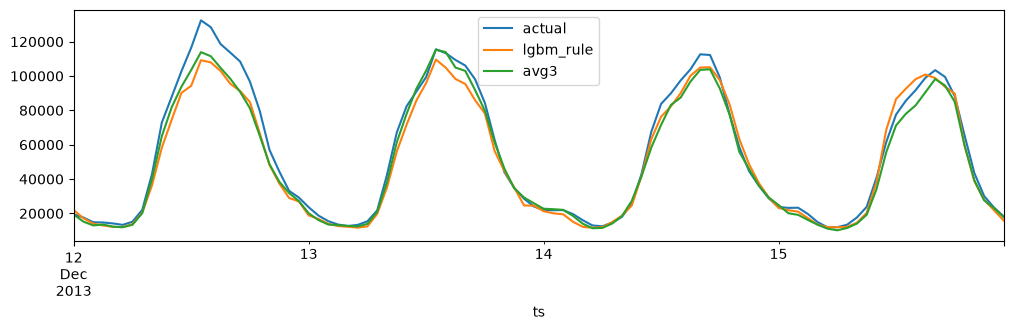

In [11]:
# 1.Alignment and silent NaNs (mean() skips NaN without warning)
p = preds["lgbm_rule"].loc[TEST_START:TEST_END]
print(len(p), len(test), int(p.isna().sum()), p.index.equals(test.index))
print({k: int(v.reindex(test.index).isna().sum()) for k, v in baselines.items()})

# 2.In sample vs test error and what the model relies on
cols = [c for c in feat_rule.columns if c != "y"]
fit = feat_rule.loc[:TRAIN_END]
m = lgb.LGBMRegressor(**params).fit(fit[cols], fit["y"])
print("in-sample MAE:", round((fit["y"] - m.predict(fit[cols])).abs().mean()))
print(pd.Series(m.feature_importances_, cols).sort_values(ascending=False))

# 3.Visual check on four test days
span = slice("2013-12-12", "2013-12-15")
ax = test.loc[span].plot(figsize=(12, 3), label="actual")
p.loc[span].plot(ax=ax, label="lgbm_rule")
baselines["naive_168h_avg3"].reindex(test.index).loc[span].plot(ax=ax, label="avg3")
ax.legend()

# 4.Positive control: allow lag_1 (not valid day ahead) diagnostic only
ctrl = feat_rule.assign(lag_1=y.shift(1)).dropna()
c_cols = [c for c in ctrl.columns if c != "y"]
mc = lgb.LGBMRegressor(**params).fit(ctrl.loc[:TRAIN_END, c_cols], ctrl.loc[:TRAIN_END, "y"])
pc = pd.Series(mc.predict(ctrl.loc[TEST_START:TEST_END, c_cols]), index=test.index)
print("positive control MAE:", round((test - pc).abs().mean()))

## Variant selection (cross-validation)

The regularized variant has the lowest mean MAE (−8% vs base) and improves all three folds. This is below the 10% margin set beforehand; it was selected anyway as the most consistent and both variants are reported on the test window.

In [12]:
variants = {
    "base": (params, None),
    "regularized": (dict(n_estimators=300, learning_rate=0.03, num_leaves=7, min_child_samples=40,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                         random_state=42, verbose=-1), None),
    "no_rolling": (params, ["roll_mean_24", "roll_mean_168"]), # columns to drop
}

train = feat_rule.loc[:TRAIN_END]
ref = baselines["naive_168h_avg3"]
rows = []
for name, (p, drop) in variants.items():
    cols = [c for c in train.columns if c != "y" and c not in (drop or [])]
    for k, (tr, va) in enumerate(TimeSeriesSplit(n_splits=3, test_size=7 * 24).split(train), 1):
        val = train.iloc[va]
        ok = ref.reindex(val.index).notna().to_numpy()
        m = lgb.LGBMRegressor(**p).fit(train.iloc[tr][cols], train.iloc[tr]["y"])
        mae = np.abs(val["y"].to_numpy() - m.predict(val[cols]))[ok].mean()
        rows.append({"variant": name, "fold": k, "MAE": round(mae)})

cv_var = pd.DataFrame(rows).pivot(index="variant", columns="fold", values="MAE")
cv_var["mean"] = cv_var.mean(axis=1).round(0)
cv_var

fold,1,2,3,mean
variant,,,,
base,4933,4252,3732,4306.0
no_rolling,4867,3809,3442,4039.0
regularized,4375,4013,3455,3948.0


## Regularized variant on the test window

Test MAE improves from 4,919 to 4,774 (−3%), a smaller gain than in cross-validation.

In [13]:
params_reg = variants["regularized"][0]
cols = [c for c in feat_rule.columns if c != "y"]
fit = feat_rule.loc[:TRAIN_END]

m = lgb.LGBMRegressor(**params_reg).fit(fit[cols], fit["y"])
print("in-sample MAE (reg):", round((fit["y"] - m.predict(fit[cols])).abs().mean()))

after = feat_rule.loc[TEST_START:]
preds["lgbm_rule_reg"] = pd.Series(m.predict(after[cols]), index=after.index)
res.loc["lgbm_rule_reg"] = pd.Series(scores(test, preds["lgbm_rule_reg"].loc[TEST_START:TEST_END]))
res.loc[["lgbm_rule_reg"], ["MAE", "RMSE", "sMAPE"]].round(1)

in-sample MAE (reg): 2325


,MAE,RMSE,sMAPE
lgbm_rule_reg,4774.2,6623.3,9.9


## Day ahead refit

For each test day the models are refitted on data up to the previous day. Prophet is run with default seasonality and with separate daily profiles for working days and off days (weekends and holidays). The conditional variant was validated on 1–8 Dec before touching the test window (MAE 4,820 vs 6,973 for default Prophet; three week average 4,459).

In [14]:
logger = logging.getLogger("cmdstanpy")
logger.addHandler(logging.NullHandler())
logger.propagate = False
logger.setLevel(logging.CRITICAL)

days = pd.date_range(TEST_START, TEST_END, freq="D")
H = pd.Timedelta(hours=1)

def lgbm_day_ahead(feat, params, days):
    cols = [c for c in feat.columns if c != "y"]
    out = []
    for day in days:
        fit = feat.loc[:day - H]
        m = lgb.LGBMRegressor(**params).fit(fit[cols], fit["y"])
        nxt = feat.loc[day:day + 23 * H]
        out.append(pd.Series(m.predict(nxt[cols]), index=nxt.index))
    return pd.concat(out)

def is_off_day(ds):
    return (ds.dt.day_of_week >= 5) | ds.dt.date.isin(HOLIDAYS)

def prophet_day_ahead(y, days, conditional=False):
    out = []
    for day in days:
        hist = y.loc[:day - H].reset_index()
        hist.columns = ["ds", "y"]
        future = pd.DataFrame({"ds": pd.date_range(day, periods=24, freq="h")})

        m = Prophet(daily_seasonality=not conditional, weekly_seasonality=True,
                    yearly_seasonality=False)
        if conditional:
            # Separate daily profiles for working days and off days (weekends, holidays)
            for d in (hist, future):
                d["off_day"] = is_off_day(d["ds"])
                d["workday"] = ~d["off_day"]
            m.add_seasonality("daily_workday", period=1, fourier_order=8, condition_name="workday")
            m.add_seasonality("daily_off", period=1, fourier_order=8, condition_name="off_day")
        m.fit(hist)
        out.append(m.predict(future).set_index("ds")["yhat"])
    return pd.concat(out)

preds["lgbm_reg_refit"] = lgbm_day_ahead(feat_rule, params_reg, days)
preds["prophet_refit"] = prophet_day_ahead(y, days)

for name in ["lgbm_reg_refit", "prophet_refit"]:
    res.loc[name] = pd.Series(scores(test, preds[name].loc[TEST_START:TEST_END]))

In [15]:
val_days = pd.date_range("2013-12-01", "2013-12-08", freq="D")
val = y.loc["2013-12-01":"2013-12-08 23:00"]

for cond in (False, True):
    p = prophet_day_ahead(y, val_days, conditional=cond)
    print("conditional" if cond else "default", round((val - p.reindex(val.index)).abs().mean()))
print("avg3", round((val - baselines["naive_168h_avg3"].reindex(val.index)).abs().mean()))

default 6973
conditional 4820
avg3 4459


In [16]:
preds["prophet_cond_refit"] = prophet_day_ahead(y, days, conditional=True)
res.loc["prophet_cond_refit"] = pd.Series(scores(test, preds["prophet_cond_refit"].loc[TEST_START:TEST_END]))

## Final comparison

On the ordinary test window the three week seasonal average is the best model (MAE 3,955, 7.3% of mean traffic). The best learned models are regularized LightGBM (4,774) and conditional Prophet (5,011). Prophet has a lower RMSE than LightGBM (6,082 vs 6,623) but a much higher sMAPE (14.6 vs 9.9); the forecast plot suggests it follows the peaks but over predicts the quiet night hours. Daily refitting did not help LightGBM (5,104).

Holiday stress test (20 Dec – 1 Jan): all models degrade strongly. LightGBM with calendar features (regularized: MAE 15.7k) is ahead of the seasonal average (19.8k), but the period was inspected during exploration, so this is indicative only. Refit models only cover the test window and are not shown.

In [17]:
res["MAE_pct_of_mean"] = (res["MAE"] / test.mean() * 100).round(1)
display(res.round(1))

stress = y.loc[STRESS_START:]
rows = {}
for name, p in {**preds, "naive_168h_avg3": baselines["naive_168h_avg3"]}.items():
    p = p.reindex(stress.index)
    if p.notna().all(): # skip models without stress period predictions
        rows[name] = scores(stress, p)
display(pd.DataFrame(rows).T.round(1))

,MAE,RMSE,sMAPE,MAE_pct_of_mean
naive_24h,6874.6,9804.8,16.3,12.6
naive_168h,5152.2,7291.0,10.2,9.5
naive_168h_avg3,3954.6,5690.6,7.8,7.3
lgbm_rule,4918.5,6934.1,9.6,9.0
lgbm_plain,4860.7,6879.2,9.5,8.9
lgbm_rule_reg,4774.2,6623.3,9.9,8.8
lgbm_reg_refit,5103.8,7123.9,10.3,9.4
prophet_refit,7225.1,8745.2,19.8,13.3
prophet_cond_refit,5010.8,6082.0,14.6,9.2


,MAE,RMSE,sMAPE
lgbm_rule,17779.2,27243.9,49.4
lgbm_plain,18038.3,27376.1,50.5
lgbm_rule_reg,15710.6,24261.0,46.4
naive_168h_avg3,19786.5,29259.8,51.3


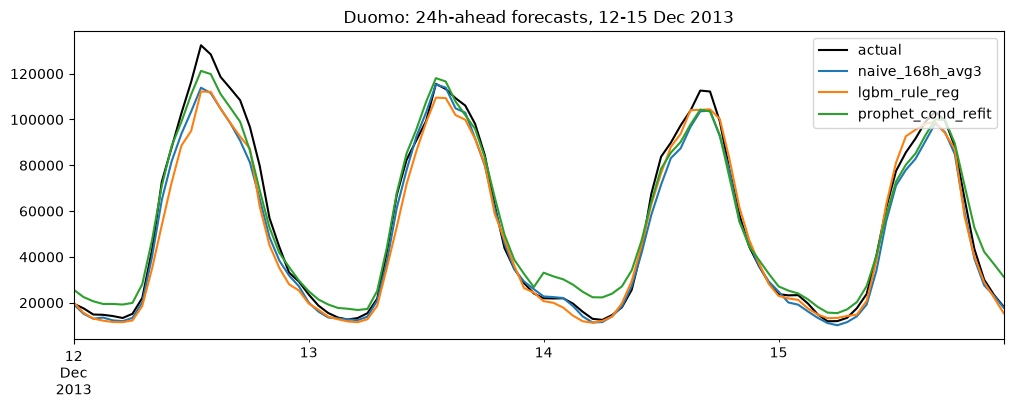

In [18]:
span = slice("2013-12-12", "2013-12-15")
fig, ax = plt.subplots(figsize=(12, 4))
test.loc[span].plot(ax=ax, label="actual", color="black")
baselines["naive_168h_avg3"].reindex(test.index).loc[span].plot(ax=ax, label="naive_168h_avg3")
preds["lgbm_rule_reg"].loc[span].plot(ax=ax, label="lgbm_rule_reg")
preds["prophet_cond_refit"].loc[span].plot(ax=ax, label="prophet_cond_refit")
ax.legend(); ax.set_title("Duomo: 24h-ahead forecasts, 12-15 Dec 2013")
ax.set_xlabel("")
fig.savefig("../outputs/figures/model_comparison_forecast.png", dpi=150, bbox_inches="tight")

In [19]:
final = res.round(1)
final.to_csv("../outputs/metrics/final_model_scores.csv")

## Limitations

- About 30 days of training data and a single zone.
- The test window was reused across several model comparisons.
- LightGBM was only lightly tuned (three variants).
- The conditional Prophet variant was motivated by looking at test window errors, then validated on a separate week.